In [ ]:
import color_code_gen_488 as cc488
import stim
import stimbposd
import numpy as np
import matplotlib.pyplot as plt

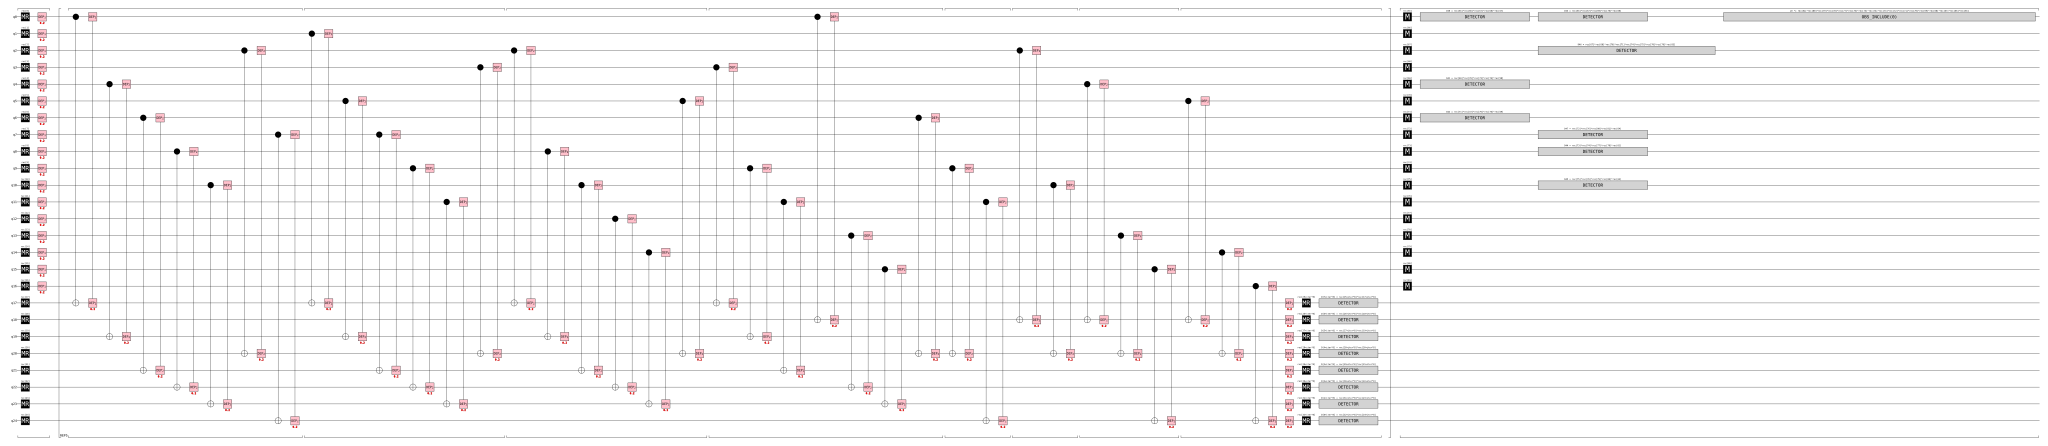

In [ ]:
cc488.square_octogon_color_code(5).build_circuit(0.2).diagram("timeline-svg")

In [ ]:
def count_logical_errors(circuit: stim.Circuit, num_shots: int) -> int:
    # Sample the circuit.
    sampler = circuit.compile_detector_sampler()
    detection_events, observable_flips = sampler.sample(num_shots, separate_observables=True)

    # Configure a decoder using the circuit.
    detector_error_model = circuit.detector_error_model()
    matcher = stimbposd.BPOSD(detector_error_model, max_bp_iters=300)  #.from_detector_error_model(detector_error_model)

    # Run the decoder.
    predictions = matcher.decode_batch(detection_events)

    # Count the mistakes.
    num_errors = 0
    for shot in range(num_shots):
        actual_for_shot = observable_flips[shot]
        predicted_for_shot = predictions[shot]
        if not np.array_equal(actual_for_shot, predicted_for_shot):
            num_errors += 1
    return num_errors

In [ ]:
probs = np.arange(0, 0.21, 0.01)
log_err_rates = []
num_shots = 10000

for p in probs:
    num_errs = count_logical_errors(cc488.square_octogon_color_code(5).build_circuit(p), num_shots)
    log_err_rates.append(num_errs/num_shots)

C:\Users\toris\AppData\Local\Temp\ipykernel_27336\1831981223.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


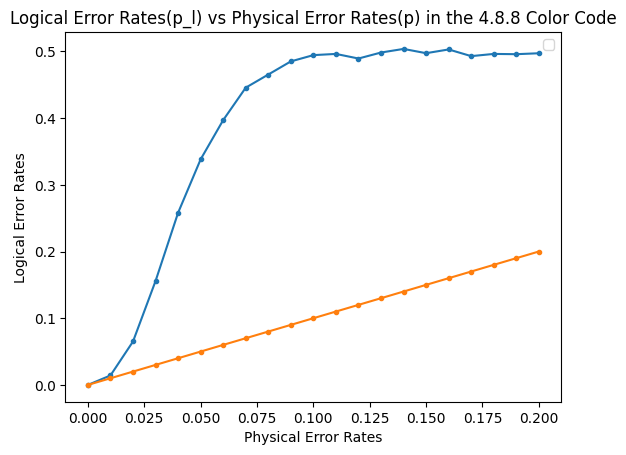

In [ ]:
plt.plot(probs, log_err_rates, '.-')
plt.plot(probs, probs, '.-')

plt.xlabel('Physical Error Rates')
plt.ylabel('Logical Error Rates')
plt.title('Logical Error Rates(p_l) vs Physical Error Rates(p) in the 4.8.8 Color Code')

    
plt.legend()